# Model Comparison Error Analysis
Comparing `openai_gpt-oss-120b` and `qwen-sql-v2` on the `test.clean.jsonl` dataset over 3 iterations.

In [49]:
import sys
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from collections import defaultdict

# Add path to import evaluation scripts
sys.path.insert(0, '/home/quanghung20gg/Documents/new/kltn/finance-agent/data_processing')
from run_evaluation_score import load_jsonl, build_gt_map, recompute_score, has_tool_error


In [50]:
def analyze_model(pred_file, gt_map, iteration=1):
    pred_data = load_jsonl(pred_file)
    results = []
    for item in pred_data:
        qid = item.get("id")
        if qid not in gt_map:
            continue
        gt = gt_map[qid]
        messages = item.get("messages", [])
        if not messages:
            continue
        
        ground_truth = gt.get("answer")
        score = recompute_score(messages, ground_truth)
        total_score = max(score.get("total_score", 0.0), 0.0)
        num_tool_calls = score.get("num_tool_calls", float("inf"))
        has_error = has_tool_error(messages)
        
        is_standard = (total_score == 1.0)
        is_advanced = (is_standard and num_tool_calls <= 8 and not has_error)
        
        status = 'failed'
        reason = 'N/A'
        if is_advanced:
            status = 'advanced'
        elif is_standard:
            status = 'standard_only'
            if has_error and num_tool_calls > 8:
                reason = 'both_error_and_tools'
            elif has_error:
                reason = 'tool_error'
            else:
                reason = 'too_many_tools'
            
        results.append({
            'id': qid,
            'status': status,
            'reason': reason,
            'family': gt.get('question_family', 'unknown'),
            'answer_type': gt.get('answer_type', 'unknown'),
            'subtype': gt.get('question_subtype', 'unknown'),
            'hops': gt.get('reasoning_hops', 0),
            'iteration': iteration
        })
    return pd.DataFrame(results)


In [51]:
gt_file = '/home/quanghung20gg/Documents/new/kltn/finance-agent/data_processing/data_mix_v5/test.clean.jsonl'

gpt_files = [
    '/home/quanghung20gg/Documents/new/kltn/finance-agent/data/test_result/sql/eval_test_results_openrouter_openai_gpt-oss-120b_iter1.jsonl',
    '/home/quanghung20gg/Documents/new/kltn/finance-agent/data/test_result/sql/eval_test_results_openrouter_openai_gpt-oss-120b_iter2.jsonl',
    '/home/quanghung20gg/Documents/new/kltn/finance-agent/data/test_result/sql/eval_test_results_openrouter_openai_gpt-oss-120b_iter3.jsonl'
]

qwen_files = [
    '/home/quanghung20gg/Documents/new/kltn/finance-agent/data/test_result/sql/eval_test_results_vllm_qwen-sql-v2_iter1.jsonl',
    '/home/quanghung20gg/Documents/new/kltn/finance-agent/data/test_result/sql/eval_test_results_vllm_qwen-sql-v2_iter2.jsonl',
    '/home/quanghung20gg/Documents/new/kltn/finance-agent/data/test_result/sql/eval_test_results_vllm_qwen-sql-v2_iter3.jsonl'
]

gt_data = load_jsonl(gt_file)
gt_map = build_gt_map(gt_data)

dfs = []
for i, file in enumerate(gpt_files, 1):
    df = analyze_model(file, gt_map, iteration=i)
    df['model'] = 'GPT-OSS-120B'
    dfs.append(df)

for i, file in enumerate(qwen_files, 1):
    df = analyze_model(file, gt_map, iteration=i)
    df['model'] = 'Qwen3-4B-LoRA-4e'
    dfs.append(df)

df_all = pd.concat(dfs)


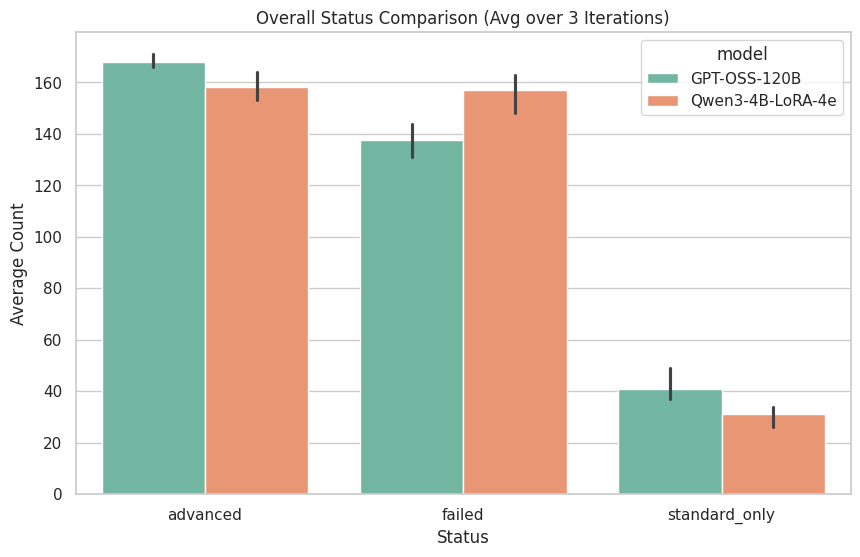

In [52]:
# Set seaborn style
sns.set_theme(style="whitegrid")

# Overall Status Comparison
status_counts = df_all.groupby(['model', 'iteration', 'status']).size().reset_index(name='count')
plt.figure(figsize=(10, 6))
sns.barplot(data=status_counts, x='status', y='count', hue='model', palette='Set2')
plt.title('Overall Status Comparison (Avg over 3 Iterations)')
plt.ylabel('Average Count')
plt.xlabel('Status')
plt.show()


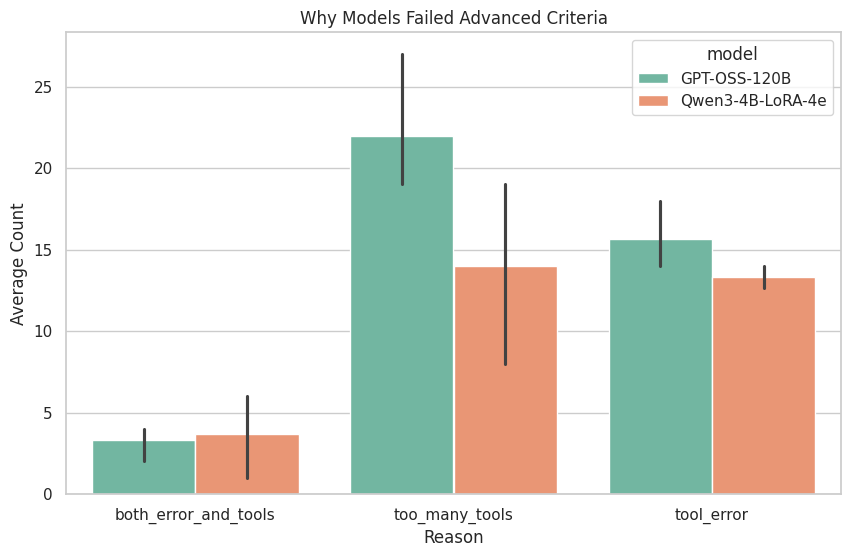

In [60]:
# Standard vs Advanced Gap Analysis
df_standard_only = df_all[df_all['status'] == 'standard_only']
gap_counts = df_standard_only.groupby(['model', 'iteration', 'reason']).size().reset_index(name='count')
plt.figure(figsize=(10, 6))
sns.barplot(data=gap_counts, x='reason', y='count', hue='model', palette='Set2')
plt.title('Why Models Failed Advanced Criteria')
plt.ylabel('Average Count')
plt.xlabel('Reason')
plt.show()


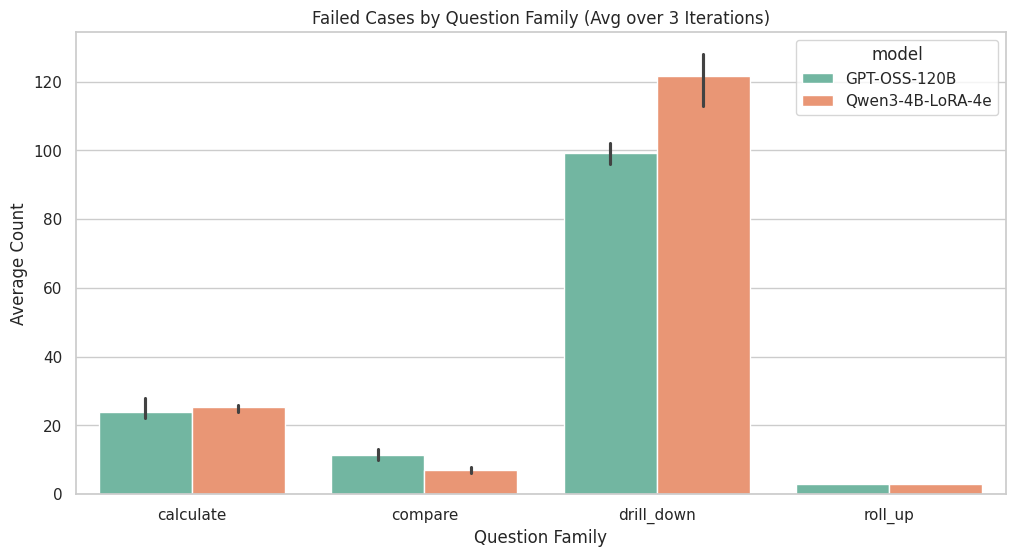

In [ ]:
# Failures by Family
df_failed = df_all[df_all['status'] == 'failed']
family_counts = df_failed.groupby(['model', 'iteration', 'family']).size().reset_index(name='count')
plt.figure(figsize=(12, 6))
sns.barplot(data=family_counts, x='family', y='count', hue='model', palette='Set2')
plt.title('Failed Cases by Question Family')
plt.ylabel('Average Count')
plt.xlabel('Question Family')
plt.show()


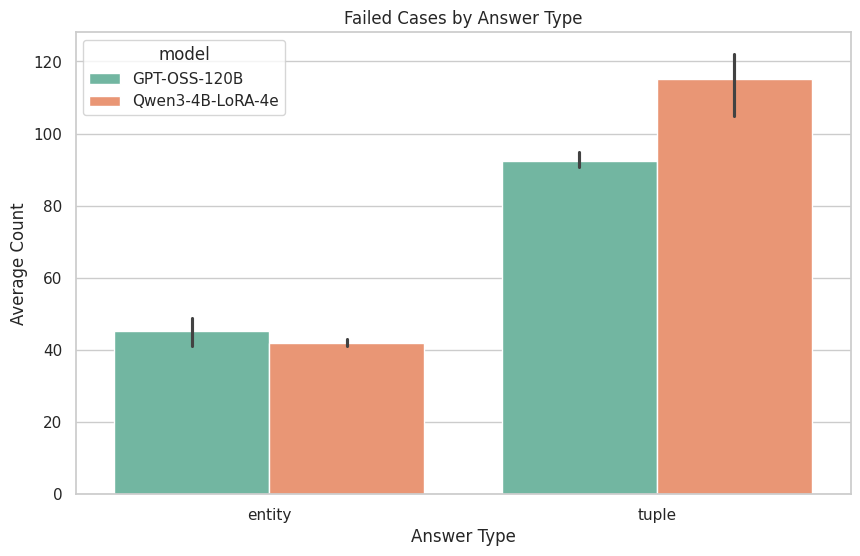

In [59]:
# Failures by Answer Type
ans_counts = df_failed.groupby(['model', 'iteration', 'answer_type']).size().reset_index(name='count')
plt.figure(figsize=(10, 6))
sns.barplot(data=ans_counts, x='answer_type', y='count', hue='model', palette='Set2')
plt.title('Failed Cases by Answer Type')
plt.ylabel('Average Count')
plt.xlabel('Answer Type')
plt.show()


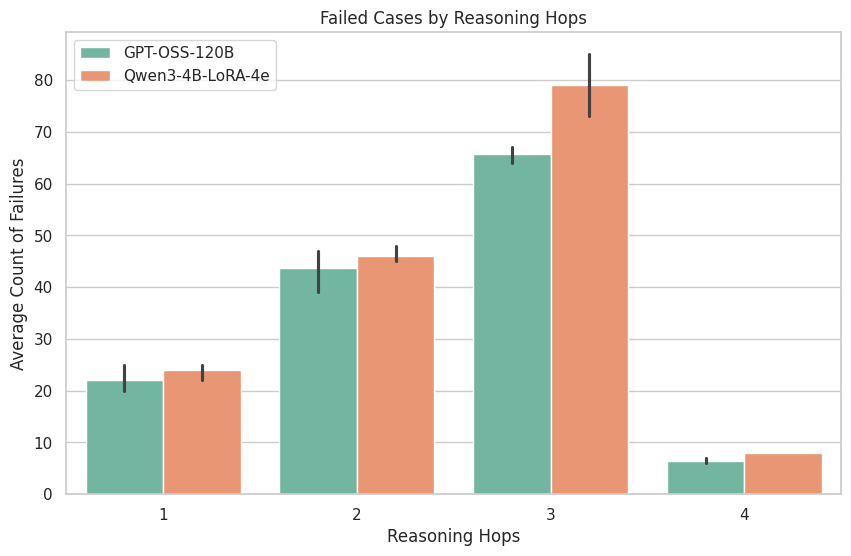

In [58]:
# Failures by Reasoning Hops
df_failed_hops = df_failed.groupby(['model', 'iteration', 'hops']).size().reset_index(name='count')
df_avg_hops = df_failed_hops.groupby(['model', 'hops'])['count'].mean().reset_index()
df_avg_hops['cum_pct'] = df_avg_hops.groupby('model')['count'].cumsum() / df_avg_hops.groupby('model')['count'].transform('sum') * 100

fig, ax1 = plt.subplots(figsize=(10, 6))
sns.barplot(data=df_failed_hops, x='hops', y='count', hue='model', palette='Set2', ax=ax1)
ax1.set_title('Failed Cases by Reasoning Hops')
ax1.set_ylabel('Average Count of Failures')
ax1.set_xlabel('Reasoning Hops')

# Clean up legends
handles1, labels1 = ax1.get_legend_handles_labels()
ax1.legend(handles1, labels1, loc='upper left')

plt.show()


/tmp/ipykernel_99103/2608169141.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_failed['subtype_label'] = df_failed['subtype'].map(lambda x: subtype_mapping.get(x, x.replace('_', ' ').title()))


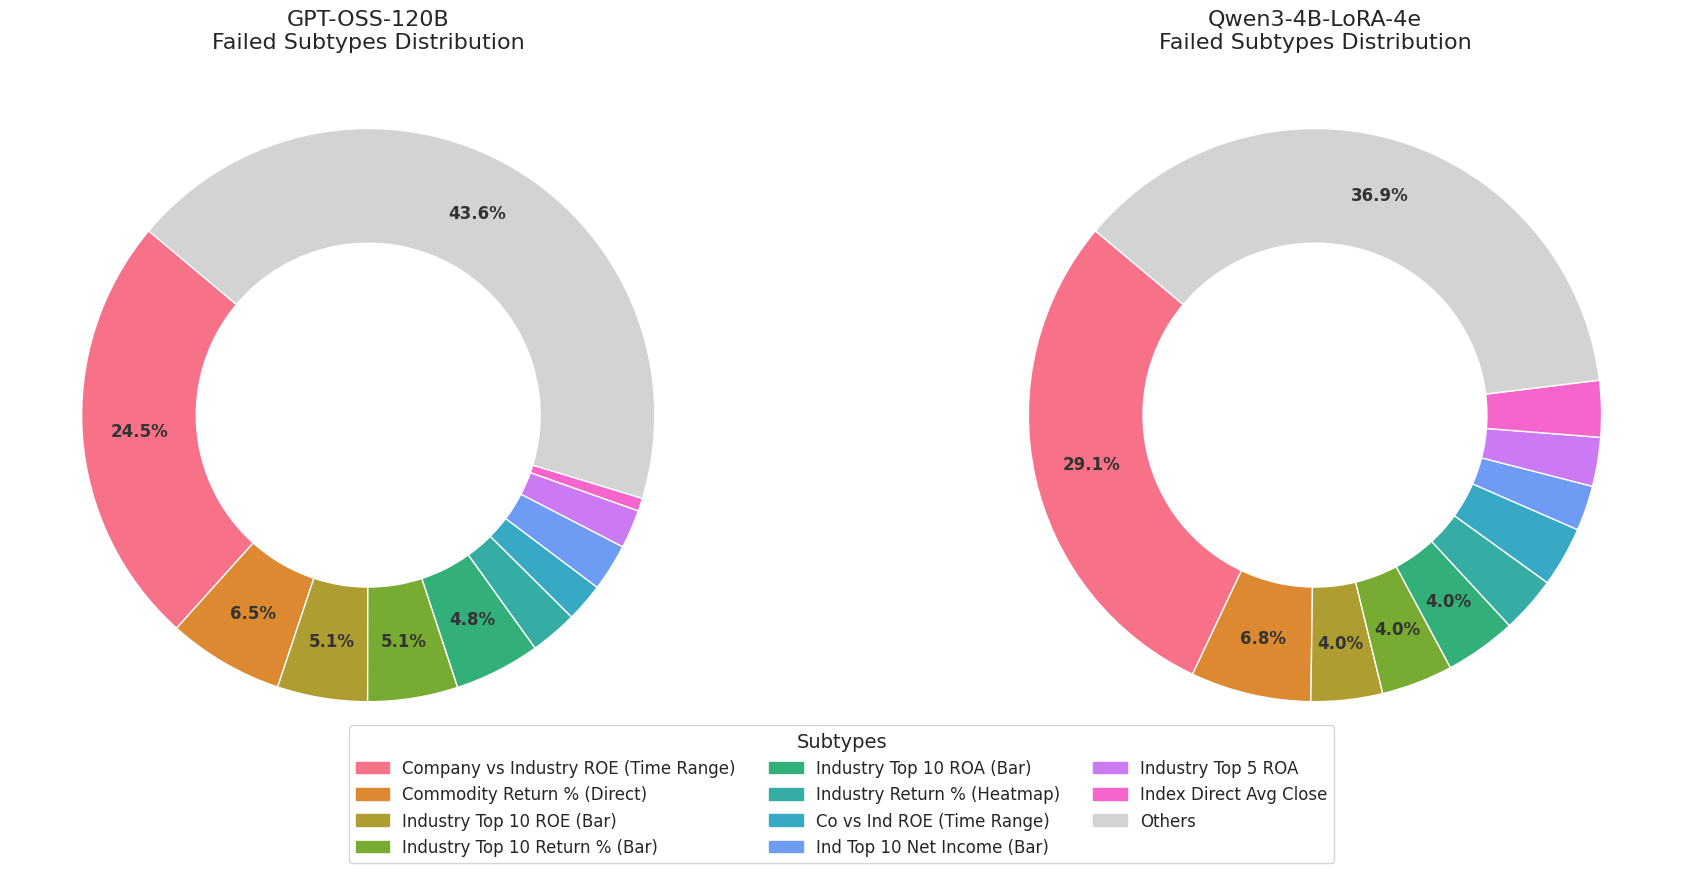

In [61]:
# Top 10 Failed Subtypes + Others (Donut Charts)
subtype_mapping = {
    'company_vs_industry_time_range_ROE': 'Company vs Industry ROE (Time Range)',
    'commodity_direct_return_pct': 'Commodity Return % (Direct)',
    'visualize_industry_top10_bar_return_pct': 'Industry Top 10 Return % (Bar)',
    'visualize_industry_top10_bar_ROA': 'Industry Top 10 ROA (Bar)',
    'visualize_industry_top10_bar_ROE': 'Industry Top 10 ROE (Bar)',
    'visualize_industry_heatmap_return_pct': 'Industry Return % (Heatmap)',
    'industry_top5_ROA': 'Industry Top 5 ROA',
    'ambiguous::company_vs_industry_time_range_ROE': 'Co vs Ind ROE (Time Range)',
    'visualize_industry_top10_bar_net_income': 'Ind Top 10 Net Income (Bar)',
    'industry_top10_ROE': 'Industry Top 10 ROE'
}

df_failed['subtype_label'] = df_failed['subtype'].map(lambda x: subtype_mapping.get(x, x.replace('_', ' ').title()))

# Find top 10 globally across all iterations
avg_subtype_counts = df_failed.groupby('subtype_label').size() / 3.0
top_10_labels = avg_subtype_counts.nlargest(10).index.tolist()

# Define a fixed color map for consistency across charts
colors = sns.color_palette('husl', len(top_10_labels))
color_map = {label: colors[i] for i, label in enumerate(top_10_labels)}
color_map['Others'] = '#d3d3d3'  # Distinct light grey for Others

models = df_failed['model'].unique()
fig, axes = plt.subplots(1, len(models), figsize=(20, 8))

for ax, model in zip(axes, models):
    model_data = df_failed[df_failed['model'] == model]
    # Average counts for this model over 3 iterations
    counts = model_data['subtype_label'].value_counts() / 3.0
    
    top_counts = counts[counts.index.isin(top_10_labels)]
    other_count = counts[~counts.index.isin(top_10_labels)].sum()
    
    plot_data = top_counts.copy()
    if other_count > 0:
        plot_data['Others'] = other_count
        
    # Ensure consistent order based on the global top 10 list
    order = [lbl for lbl in top_10_labels if lbl in plot_data.index]
    if 'Others' in plot_data:
        order.append('Others')
    plot_data = plot_data.reindex(order)
    
    # Plot donut chart
    wedges, texts, autotexts = ax.pie(
        plot_data, 
        autopct=lambda p: f'{p:.1f}%' if p >= 4 else '', 
        startangle=140, 
        colors=[color_map[lbl] for lbl in plot_data.index],
        wedgeprops=dict(width=0.4, edgecolor='w'),
        pctdistance=0.80, # Middle of the donut ring
        textprops={'fontsize': 12, 'weight': 'bold', 'color': '#333333'}
    )
    ax.set_title(f'{model}\nFailed Subtypes Distribution', fontsize=16)

# Add shared legend at the bottom
handles = [plt.Rectangle((0,0),1,1, color=color_map[lbl]) for lbl in top_10_labels + ['Others']]
fig.legend(handles, top_10_labels + ['Others'], title='Subtypes', loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.1), fontsize=12, title_fontsize=14)

plt.tight_layout()
plt.show()
